<a href="https://colab.research.google.com/github/huynhtamtri2006-gif/TH---MACHINE_LEARNING/blob/main/tuan_2/B%C3%80I_T%E1%BA%ACP_BU%E1%BB%94I_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Bài 1.Thực nghiệm lại code mẫu KNN với các yêu cầu**

1. Thực nghiệm với các giá trị K khác nhau để tìm ra giá trị K tối ưu.

2. Chuẩn hóa dữ liệu đầu vào để tránh ảnh hưởng của các đặc trưng có đơn vị hoặc phạm vi khác nhau.

3. Thực nghiệm với các đơn vị tính khoảng cách khác nhau như khoảng cách Manhattan, Minkowski để xem sự thay đổi trong hiệu quả của mô hình.

In [1]:
#Khai báo thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [2]:
#Đọc dữ liệu và khám phá
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df['target'] = y

print("Kích thước dữ liệu:", df.shape)
print("Tên các lớp:", iris.target_names)

display(df.head(10))
display(df.describe())

print("Số lượng giá trị thiếu:")
print(df.isnull().sum())

Kích thước dữ liệu: (150, 5)
Tên các lớp: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
5,5.4,3.9,1.7,0.4,0
6,4.6,3.4,1.4,0.3,0
7,5.0,3.4,1.5,0.2,0
8,4.4,2.9,1.4,0.2,0
9,4.9,3.1,1.5,0.1,0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


Số lượng giá trị thiếu:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [3]:
#Chia tập dữ liệu
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Tập huấn luyện:", X_train.shape)
print("Tập kiểm tra:", X_test.shape)

Tập huấn luyện: (120, 4)
Tập kiểm tra: (30, 4)


In [5]:
#Xây dựng mô hình KNN ban đầu
#mô hình cơ sở với K = 5 và khoảng cách Euclidean.
knn = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean'
)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Giá trị K:", 5)
print("Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=iris.target_names
))

Giá trị K: 5
Accuracy: 1.0

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



# **1. Thử nghiệm các giá trị K khác nhau**

In [6]:
#Tìm giá trị K tối ưu
k_values = range(1, 31)
accuracy_list = []

for k in k_values:

    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric='euclidean'
    )

    scores = cross_val_score(
        knn, X_train, y_train,
        cv=cv,
        scoring='accuracy'
    )

    accuracy_list.append(scores.mean())

df_k = pd.DataFrame({
    'K': list(k_values),
    'CV Accuracy': accuracy_list
})

display(df_k)

best_k = df_k.loc[df_k['CV Accuracy'].idxmax(), 'K']
best_accuracy = max(accuracy_list)

print("K tối ưu:", best_k)
print("Accuracy tốt nhất:", best_accuracy)

,K,CV Accuracy
0,1,0.958333
1,2,0.958333
2,3,0.958333
3,4,0.950000
4,5,0.975000
5,6,0.966667
6,7,0.966667
7,8,0.966667
8,9,0.958333
9,10,0.958333


K tối ưu: 5
Accuracy tốt nhất: 0.975


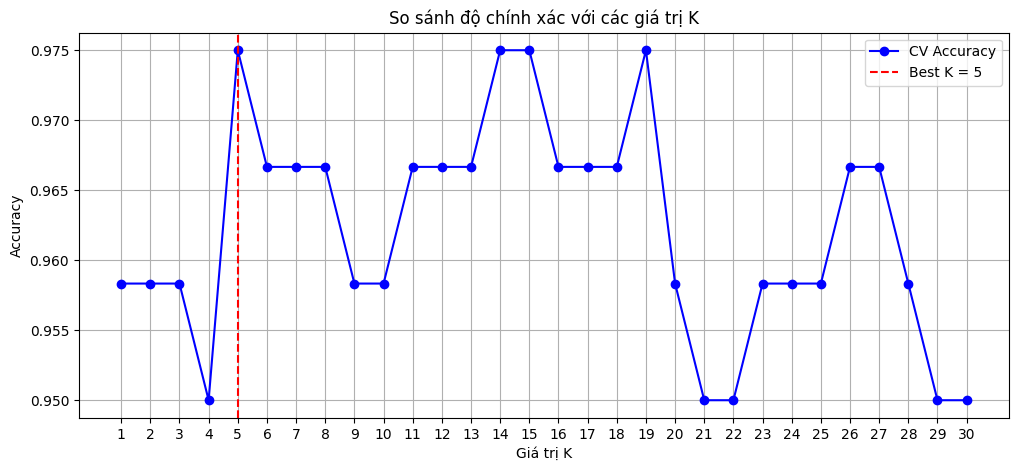

K tối ưu: 5
Accuracy tốt nhất: 0.975


In [8]:
#Vẽ biểu đồ Accuracy theo K
plt.figure(figsize=(12, 5))

plt.plot(
    k_values,
    accuracy_list,
    marker='o',
    color='blue',
    label='CV Accuracy'
)

plt.axvline(
    x=best_k,
    color='red',
    linestyle='--',
    label=f'Best K = {best_k}'
)

plt.xlabel('Giá trị K')
plt.ylabel('Accuracy')
plt.title('So sánh độ chính xác với các giá trị K')
plt.xticks(list(k_values))
plt.legend()
plt.grid()
plt.show()

print("K tối ưu:", best_k)
print("Accuracy tốt nhất:", best_accuracy)

# **2. Chuẩn hóa dữ liệu đầu vào**


In [9]:
#Thực hiện chuẩn hóa dữ liệu
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Dữ liệu trước chuẩn hóa:")
print(X_train[:5])

print("\nDữ liệu sau chuẩn hóa:")
print(X_train_scaled[:5])

print("\nMean sau chuẩn hóa:")
print(X_train_scaled.mean(axis=0))

print("\nStandard deviation sau chuẩn hóa:")
print(X_train_scaled.std(axis=0))

Dữ liệu trước chuẩn hóa:
[[4.4 2.9 1.4 0.2]
 [4.9 2.5 4.5 1.7]
 [6.8 2.8 4.8 1.4]
 [4.9 3.1 1.5 0.1]
 [5.5 2.5 4.  1.3]]

Dữ liệu sau chuẩn hóa:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]

Mean sau chuẩn hóa:
[-1.20829273e-15 -2.03679666e-15  4.99600361e-16  1.67458640e-15]

Standard deviation sau chuẩn hóa:
[1. 1. 1. 1.]


In [10]:
#So sánh trước và sau chuẩn hóa
knn_before = KNeighborsClassifier(
    n_neighbors=int(best_k),
    metric='euclidean'
)

knn_after = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors=int(best_k),
        metric='euclidean'
    )
)

acc_before = cross_val_score(
    knn_before, X_train, y_train,
    cv=cv
).mean()

acc_after = cross_val_score(
    knn_after, X_train, y_train,
    cv=cv
).mean()

df_scale = pd.DataFrame({
    'Phương pháp': [
        'Không chuẩn hóa',
        'Có chuẩn hóa'
    ],
    'CV Accuracy': [
        acc_before,
        acc_after
    ]
})

display(df_scale)

print("Mức chênh lệch:", acc_after - acc_before)

,Phương pháp,CV Accuracy
0,Không chuẩn hóa,0.975000
1,Có chuẩn hóa,0.958333


Mức chênh lệch: -0.016666666666666607


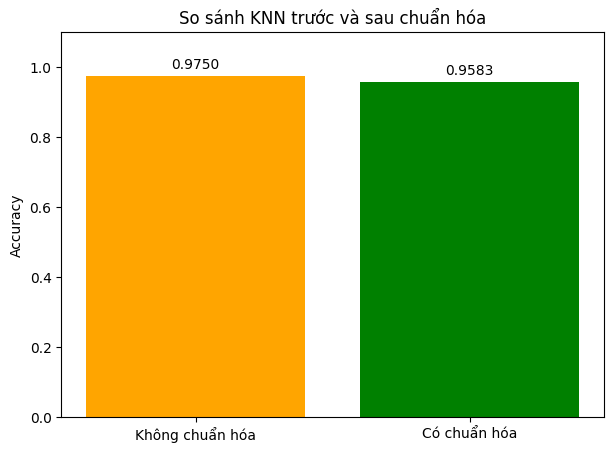

In [11]:
#Vẽ biểu đò so sánh
plt.figure(figsize=(7, 5))

plt.bar(
    ['Không chuẩn hóa', 'Có chuẩn hóa'],
    [acc_before, acc_after],
    color=['orange', 'green']
)

plt.ylim(0, 1.1)

plt.text(0, acc_before + 0.02,
         f'{acc_before:.4f}', ha='center')

plt.text(1, acc_after + 0.02,
         f'{acc_after:.4f}', ha='center')

plt.ylabel('Accuracy')
plt.title('So sánh KNN trước và sau chuẩn hóa')
plt.show()

# **3. Thử nghiệm các phương pháp tính khoảng cách**

In [12]:
#Thực nghiệm các loại khoảng cách
metrics = ['euclidean', 'manhattan', 'minkowski']

distance_results = []

for metric in metrics:

    knn = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            n_neighbors=int(best_k),
            metric=metric,
            p=3
        )
    )

    scores = cross_val_score(
        knn, X_train, y_train,
        cv=cv,
        scoring='accuracy'
    )

    distance_results.append({
        'Distance': metric,
        'K': best_k,
        'CV Accuracy': scores.mean()
    })

df_distance = pd.DataFrame(distance_results)

display(df_distance)

best_metric = df_distance.loc[
    df_distance['CV Accuracy'].idxmax(),
    'Distance'
]

print("Khoảng cách tốt nhất:", best_metric)

,Distance,K,CV Accuracy
0,euclidean,5,0.958333
1,manhattan,5,0.958333
2,minkowski,5,0.941667


Khoảng cách tốt nhất: euclidean


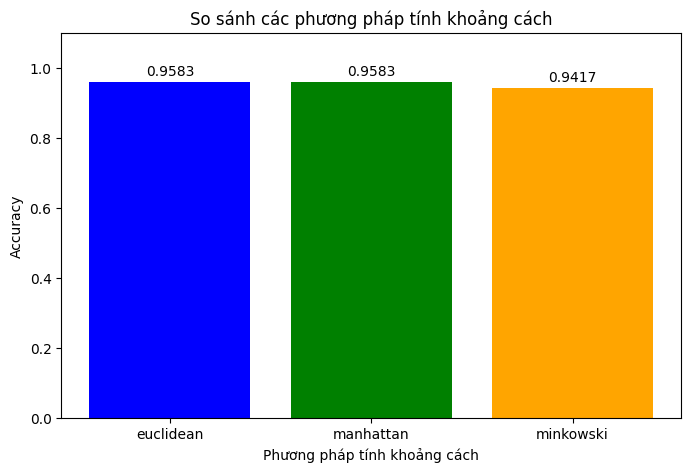

In [13]:
#Vẽ biểu đồ so sánh khoảng cách
plt.figure(figsize=(8, 5))

plt.bar(
    df_distance['Distance'],
    df_distance['CV Accuracy'],
    color=['blue', 'green', 'orange']
)

for i, acc in enumerate(df_distance['CV Accuracy']):
    plt.text(i, acc + 0.02,
             f'{acc:.4f}', ha='center')

plt.ylim(0, 1.1)
plt.xlabel('Phương pháp tính khoảng cách')
plt.ylabel('Accuracy')
plt.title('So sánh các phương pháp tính khoảng cách')
plt.show()

# **Tổng hợp và xây dựng mô hình KNN tối ưu**

In [14]:
#Kết hợp các tham số thực nghiệm
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

param_grid = {
    'scaler': [StandardScaler(), 'passthrough'],
    'knn__n_neighbors': list(range(1, 31)),
    'knn__metric': [
        'euclidean',
        'manhattan',
        'minkowski'
    ],
    'knn__p': [3]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Tham số tối ưu:")
print(grid_search.best_params_)

print("\nCV Accuracy tốt nhất:")
print(grid_search.best_score_)

Tham số tối ưu:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 5, 'knn__p': 3, 'scaler': 'passthrough'}

CV Accuracy tốt nhất:
0.975


In [15]:
#Đánh giá mô hình cuối cùng
best_model = grid_search.best_estimator_

y_pred_final = best_model.predict(X_test)

final_accuracy = accuracy_score(
    y_test, y_pred_final
)

print("Accuracy trên tập kiểm tra:", final_accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_final,
    target_names=iris.target_names
))

Accuracy trên tập kiểm tra: 1.0

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



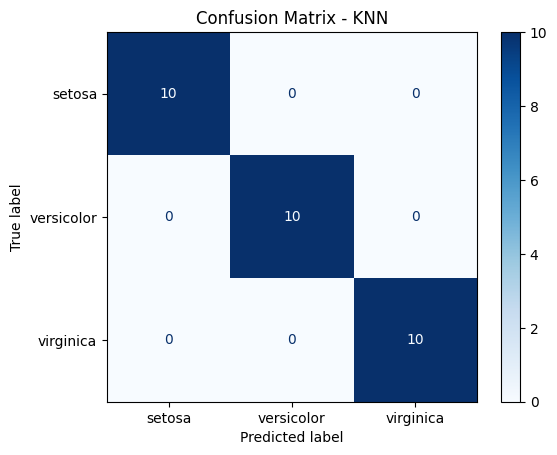

In [16]:
#Vẽ ma trận nhầm lẫn
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    display_labels=iris.target_names,
    cmap='Blues'
)

plt.title('Confusion Matrix - KNN')
plt.show()